First Five Rows
   Area  Bedrooms  Bathrooms  Floors  Age  Garage  Distance_to_City   Price
0  1200         2          1       1   20       1                15  250000
1  1500         3          2       1   15       1                12  300000
2  1800         3          2       2   10       2                10  350000
3  2400         4          3       2    8       2                 8  450000
4  3000         4          3       2    6       2                 7  550000

Missing Values
Area                0
Bedrooms            0
Bathrooms           0
Floors              0
Age                 0
Garage              0
Distance_to_City    0
Price               0
dtype: int64

Summary Statistics
              Area   Bedrooms  Bathrooms     Floors       Age     Garage  \
count    10.000000  10.000000  10.000000  10.000000  10.00000  10.000000   
mean   3240.000000   4.500000   3.500000   2.500000   7.40000   2.500000   
std    1507.905096   1.581139   1.581139   1.080123   6.07728   1.080123   

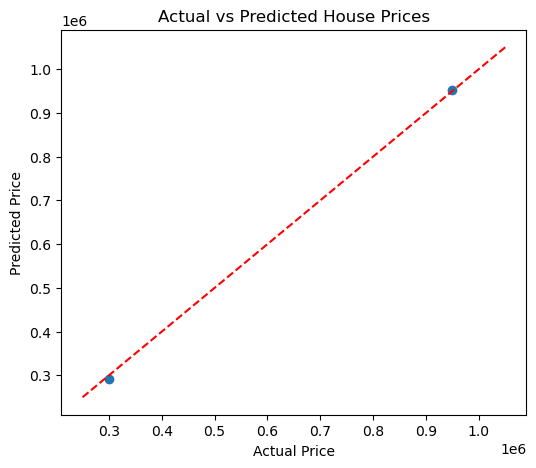

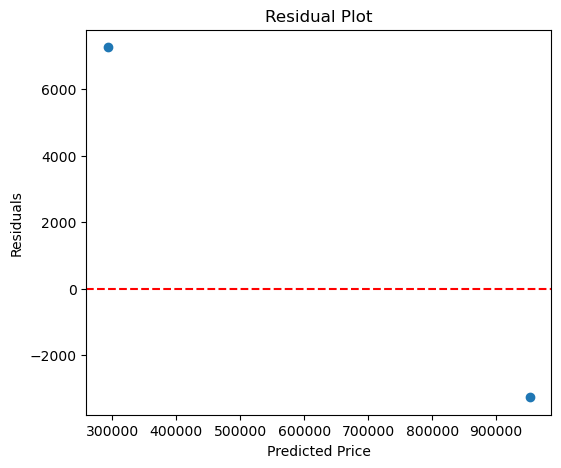

In [4]:
# -------------------------------
# Step 1: Import Libraries
# -------------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# -------------------------------
# Step 2: Create Sample Dataset
# -------------------------------
data = {
    'Area': [1200,1500,1800,2400,3000,3500,4000,4500,5000,5500],
    'Bedrooms': [2,3,3,4,4,5,5,6,6,7],
    'Bathrooms': [1,2,2,3,3,4,4,5,5,6],
    'Floors': [1,1,2,2,2,3,3,3,4,4],
    'Age': [20,15,10,8,6,5,4,3,2,1],
    'Garage': [1,1,2,2,2,3,3,3,4,4],
    'Distance_to_City': [15,12,10,8,7,6,5,4,3,2],
    'Price': [250000,300000,350000,450000,550000,650000,750000,850000,950000,1050000]
}

df = pd.DataFrame(data)

# -------------------------------
# Step 3: Exploratory Data Analysis
# -------------------------------
print("First Five Rows")
print(df.head())

print("\nMissing Values")
print(df.isnull().sum())

print("\nSummary Statistics")
print(df.describe())

# -------------------------------
# Step 4: Separate Features and Target
# -------------------------------
X = df.drop('Price', axis=1)
y = df['Price']

# -------------------------------
# Step 5: Train-Test Split
# -------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# -------------------------------
# Step 6: Feature Scaling
# -------------------------------
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# -------------------------------
# Step 7: Train Linear Regression Model
# -------------------------------
model = LinearRegression()
model.fit(X_train_scaled, y_train)

# -------------------------------
# Step 8: Prediction
# -------------------------------
y_pred = model.predict(X_test_scaled)

# -------------------------------
# Step 9: Model Evaluation
# -------------------------------
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nModel Evaluation")
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R² Score:", r2)

# -------------------------------
# Step 10: Regression Coefficients
# -------------------------------
coef = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
})

print("\nRegression Coefficients")
print(coef)

# -------------------------------
# Step 11: Actual vs Predicted Plot
# -------------------------------
plt.figure(figsize=(6,5))
plt.scatter(y_test, y_pred)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--')
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")
plt.show()

# -------------------------------
# Step 12: Residual Plot
# -------------------------------
residuals = y_test - y_pred

plt.figure(figsize=(6,5))
plt.scatter(y_pred, residuals)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

   Year  Present_Price  Kms_Driven Fuel_Type Seller_Type Transmission  Owner  \
0  2015            5.5       50000    Petrol      Dealer       Manual      0   
1  2016            7.2       30000    Diesel      Dealer       Manual      1   
2  2017            9.8       20000    Petrol  Individual    Automatic      0   
3  2014            4.5       70000    Diesel      Dealer       Manual      2   
4  2018           10.5       15000    Petrol  Individual    Automatic      0   

   Selling_Price  
0            4.5  
1            6.0  
2            8.5  
3            3.5  
4            9.5  
MAE: 1.035237707539764
MSE: 1.1447960641018895
RMSE: 1.069951430720988
R2 Score: 0.8168326297436976


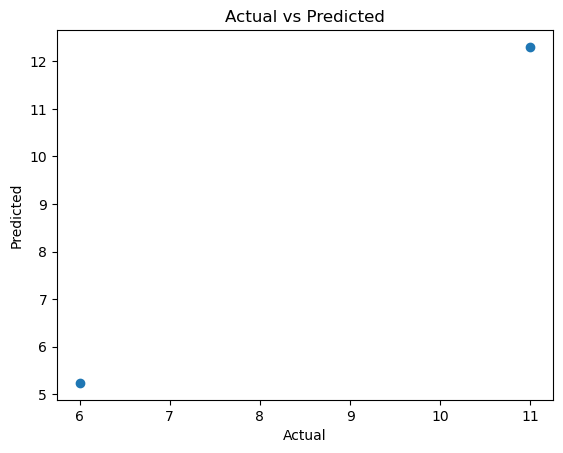

In [4]:
# Imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# Create Dataset

data = {
    'Year': [2015, 2016, 2017, 2014, 2018, 2013, 2019, 2012, 2020, 2011],
    'Present_Price': [5.5, 7.2, 9.8, 4.5, 10.5, 3.8, 11.2, 3.2, 12.5, 2.8],
    'Kms_Driven': [50000, 30000, 20000, 70000, 15000, 90000, 10000, 110000, 8000, 120000],
    'Fuel_Type': ['Petrol', 'Diesel', 'Petrol', 'Diesel', 'Petrol', 'CNG', 'Diesel', 'Petrol', 'Petrol', 'CNG'],
    'Seller_Type': ['Dealer', 'Dealer', 'Individual', 'Dealer', 'Individual', 'Individual', 'Dealer', 'Individual', 'Dealer', 'Individual'],
    'Transmission': ['Manual', 'Manual', 'Automatic', 'Manual', 'Automatic', 'Manual', 'Automatic', 'Manual', 'Automatic', 'Manual'],
    'Owner': [0, 1, 0, 2, 0, 1, 0, 2, 0, 3],
    'Selling_Price': [4.5, 6.0, 8.5, 3.5, 9.5, 2.8, 10.2, 2.5, 11.0, 2.0]
}

df = pd.DataFrame(data)


# EDA

print(df.head())


# Feature Engineering (optional)

df['Car_Age'] = 2026 - df['Year']
df.drop('Year', axis=1, inplace=True)


# Features & Target

X = df.drop('Selling_Price', axis=1)
y = df['Selling_Price']


# Convert categorical → numeric

X = pd.get_dummies(X, drop_first=True)


# Train-Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


# Scaling

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# Model Training

model = LinearRegression()
model.fit(X_train_scaled, y_train)


# Prediction

y_pred = model.predict(X_test_scaled)


# Evaluation

print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))


# Plot
plt.scatter(y_test, y_pred)
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted")
plt.show()

# plt.figure(figsize=(6,5))
# plt.scatter(y_test, y_pred)
# plt.xlabel("Actual")
# plt.ylabel("Predicted")
# plt.title("Actual vs Predicted")
# plt.show()